# 🛍️ Customer Segmentation Analysis using RFM & K-Means Clustering

**Domain:** E-Commerce & Customer Analytics  
**Methodology:** RFM Feature Engineering, Log Transformation, StandardScaler, K-Means Clustering, PCA  
**Target:** Discover customer personas, evaluate the Pareto principle, and formulate targeted marketing campaigns.

---

### 📌 Business Objective
A direct-to-consumer online retail brand wants to improve customer retention and marketing return on investment (ROI). Blasting the same generic 10% discount to all customers leads to:
1. **Margin waste** on high-spending VIPs who would purchase anyway.
2. **High churn** among at-risk customers who need personalized re-engagement.
3. **Low conversion** on one-time buyers who need onboarding.

We will segment 4,000+ customers into actionable cohorts using unsupervised machine learning.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Set visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Ensure output directory exists
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
print("Libraries loaded successfully and output directory ready!")


Libraries loaded successfully and output directory ready!


## 1. Data Ingestion & Preprocessing

The raw dataset contains over 540,000 transaction line-items.
Before clustering, we must clean the data:
- Remove records without a `CustomerID` (guest checkouts cannot be clustered over time).
- Remove cancelled transactions (invoices starting with `'C'`) and returns (`Quantity <= 0`).
- Remove zero or negative `UnitPrice`.
- Calculate `TotalPrice = Quantity * UnitPrice`.


In [2]:
# Locate data file
data_paths = [
    os.path.join("..", "data", "online_retail_transactions.csv"),
    os.path.join("data", "online_retail_transactions.csv"),
    os.path.join("..", "data", "data.csv"),
    os.path.join("data", "data.csv"),
]

data_file = None
for p in data_paths:
    if os.path.exists(p):
        data_file = p
        break

if not data_file:
    raise FileNotFoundError("Could not find online_retail_transactions.csv in data/ directory.")

print(f"Loading transaction records from: {data_file}")
df = pd.read_csv(data_file, encoding="ISO-8859-1")
initial_rows = len(df)
print(f"Raw Transaction Count: {initial_rows:,}")

# Cleaning steps
df = df.dropna(subset=["CustomerID"])
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

cleaned_rows = len(df)
print(f"Cleaned Transactions: {cleaned_rows:,} (Retained {cleaned_rows/initial_rows*100:.1f}%)")
print(f"Unique Customers: {df['CustomerID'].nunique():,}")
df.head()


Loading transaction records from: ..\data\data.csv


Raw Transaction Count: 541,909


Cleaned Transactions: 397,884 (Retained 73.4%)
Unique Customers: 4,338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 2. Feature Engineering: The RFM Framework

We aggregate the line-item transactions into customer-level metrics:
- **Recency ($R$):** Days since the customer's last purchase relative to a snapshot reference date ($Max(\text{InvoiceDate}) + 1\text{ day}$).
- **Frequency ($F$):** Total count of unique orders/invoices placed by the customer.
- **Monetary ($M$):** Total spending across all purchases ($TotalPrice$).


In [3]:
# Snapshot reference date
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print(f"Analysis Snapshot Date: {snapshot_date.date()}")

# Aggregate RFM per customer
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot_date - d.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

# Filter positive monetary
rfm = rfm[rfm["Monetary"] > 0]

print(f"\nComputed RFM for {len(rfm):,} unique customers.")
rfm.describe().round(2)


Analysis Snapshot Date: 2011-12-10



Computed RFM for 4,338 unique customers.


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


## 3. Handling Distribution Skewness & Feature Scaling

### Why Transform?
Customer metrics are almost universally **heavily right-skewed** (a handful of customers place dozens of orders and spend thousands, while the vast majority make 1 or 2 small purchases).

Because **K-Means uses Euclidean distance**, extreme outliers distort the cluster centroids.
- **Log Transformation:** We apply $\log(x + 1)$ to normalize the variances and produce bell-shaped distributions.
- **StandardScaler:** Centers each feature to mean $\mu = 0$ and standard deviation $\sigma = 1$, ensuring Monetary (dollars) doesn't drown out Recency (days).


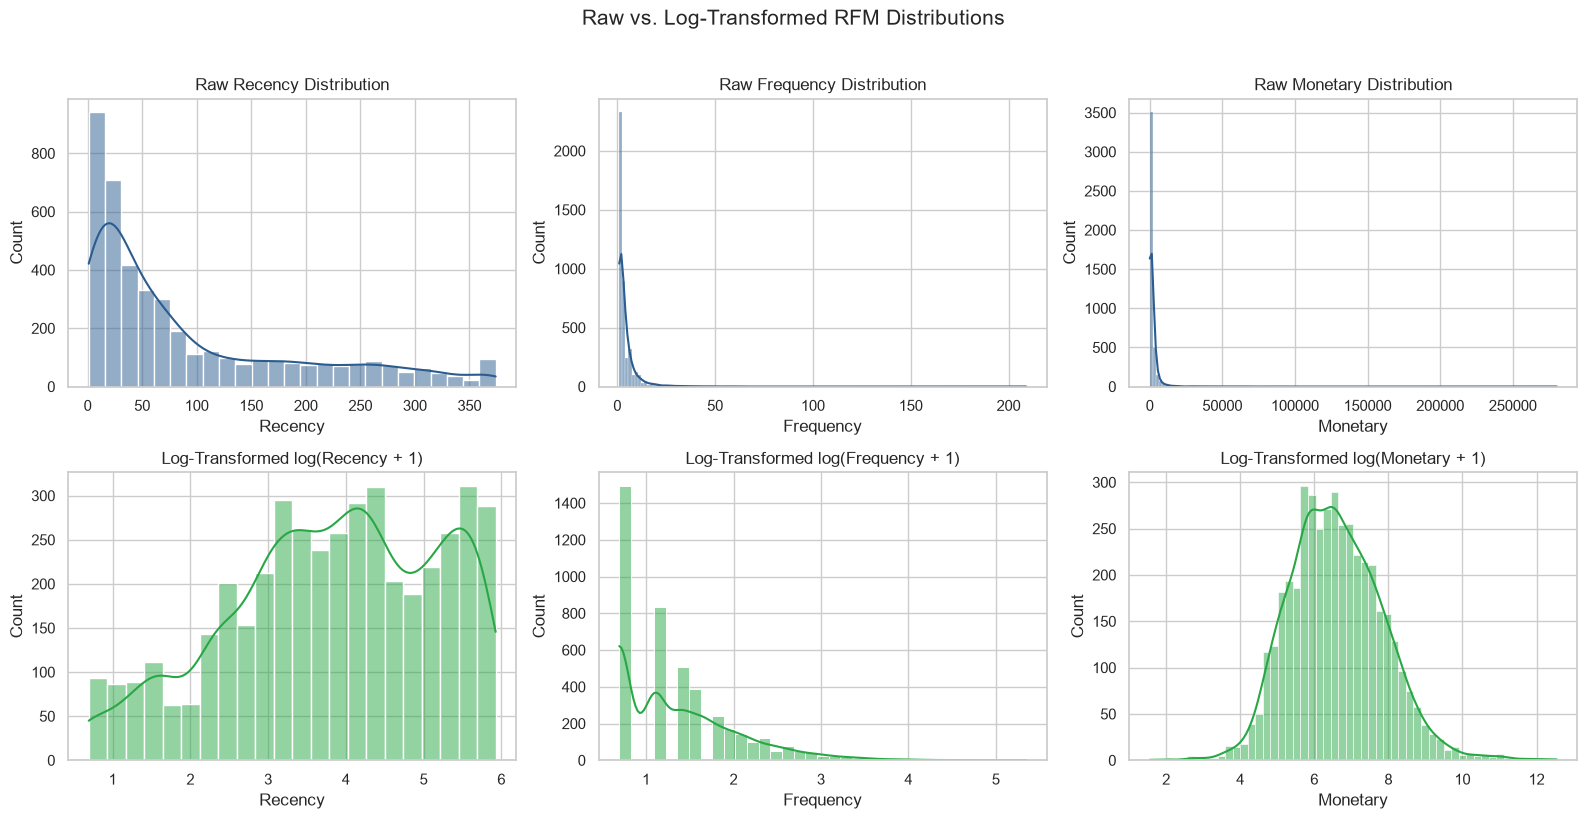

Saved distribution plot to: ..\output\rfm_distributions_skewness.png


In [4]:
# Plot Raw vs Log-Transformed Distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for idx, col in enumerate(["Recency", "Frequency", "Monetary"]):
    # Raw distribution
    sns.histplot(rfm[col], kde=True, ax=axes[0, idx], color="#2b5c8f")
    axes[0, idx].set_title(f"Raw {col} Distribution")
    
    # Log-transformed distribution
    log_vals = np.log1p(rfm[col])
    sns.histplot(log_vals, kde=True, ax=axes[1, idx], color="#28a745")
    axes[1, idx].set_title(f"Log-Transformed log({col} + 1)")

plt.suptitle("Raw vs. Log-Transformed RFM Distributions", fontsize=15, y=1.02)
plt.tight_layout()

# Save image to output
plot_skew_path = os.path.join(output_dir, "rfm_distributions_skewness.png")
plt.savefig(plot_skew_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved distribution plot to: {plot_skew_path}")


In [5]:
# Apply Log Transformation and StandardScaler
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=["Recency", "Frequency", "Monetary"])

print("Standardized Features (Mean ~ 0, Std ~ 1):")
print(rfm_scaled_df.describe().round(2))


Standardized Features (Mean ~ 0, Std ~ 1):
       Recency  Frequency  Monetary
count  4338.00    4338.00   4338.00
mean     -0.00      -0.00      0.00
std       1.00       1.00      1.00
min      -2.34      -0.96     -4.00
25%      -0.66      -0.96     -0.69
50%       0.09      -0.36     -0.06
75%       0.84       0.65      0.65
max       1.56       5.86      4.73


## 4. Hyperparameter Tuning: Determining Optimal $k$

We evaluate clustering quality using two industry-standard metrics:
1. **The Elbow Method (Inertia):** Measures within-cluster sum-of-squares (compactness). We look for the "elbow point" where adding more clusters yields diminishing returns.
2. **Silhouette Score:** Measures how well-separated each cluster is from its neighbors (ranges from -1 to +1; higher is better).


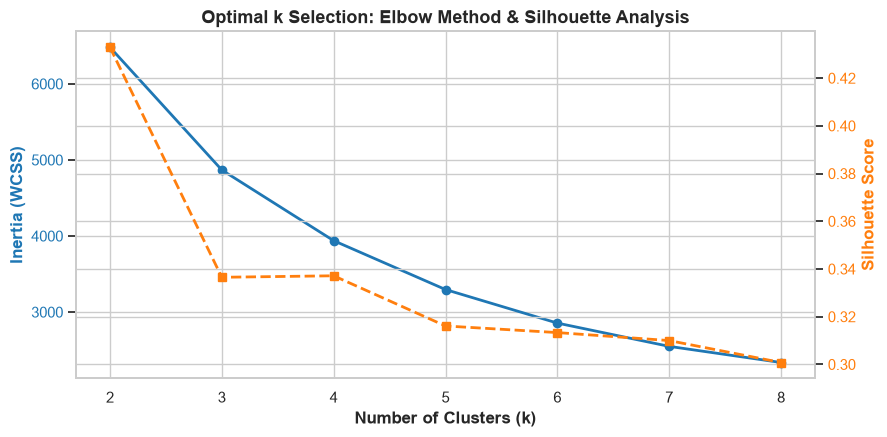

Saved optimal k plot to: ..\output\optimal_k_selection.png


In [6]:
inertias = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, km.labels_))

# Plot dual-axis Elbow & Silhouette curve
fig, ax1 = plt.subplots(figsize=(9, 4.5))

ax1.plot(k_range, inertias, marker="o", color="#1f77b4", linewidth=2, label="Inertia (Elbow)")
ax1.set_xlabel("Number of Clusters (k)", fontweight="bold")
ax1.set_ylabel("Inertia (WCSS)", color="#1f77b4", fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#1f77b4")

ax2 = ax1.twinx()
ax2.plot(k_range, silhouette_scores, marker="s", color="#ff7f0e", linewidth=2, linestyle="--", label="Silhouette Score")
ax2.set_ylabel("Silhouette Score", color="#ff7f0e", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

plt.title("Optimal k Selection: Elbow Method & Silhouette Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()

plot_k_path = os.path.join(output_dir, "optimal_k_selection.png")
plt.savefig(plot_k_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved optimal k plot to: {plot_k_path}")


## 5. Training K-Means ($k=4$) & Customer Profiling

Based on the elbow bend and business interpretability, we select **$k=4$ clusters**.
Let's train the model, assign each customer their cluster, and map the clusters to business personas.


In [7]:
# Fit K-Means with k=4
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, init="k-means++", random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Calculate cluster centroids for persona naming
cluster_stats = rfm.groupby("Cluster").agg(
    Recency_Mean=("Recency", "mean"),
    Frequency_Mean=("Frequency", "mean"),
    Monetary_Mean=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
    Customer_Count=("CustomerID", "count")
)

# Identify personas dynamically
vip_id = cluster_stats["Monetary_Mean"].idxmax()
dormant_id = cluster_stats["Recency_Mean"].idxmax()
remaining = [c for c in cluster_stats.index if c not in (vip_id, dormant_id)]
new_buyer_id = min(remaining, key=lambda c: cluster_stats.loc[c, "Recency_Mean"])
loyal_id = [c for c in remaining if c != new_buyer_id][0]

persona_map = {
    vip_id: "Champions (Super VIPs)",
    loyal_id: "Loyal Steady Buyers",
    new_buyer_id: "Recent / Potential Loyalists",
    dormant_id: "Dormant / At-Risk"
}

rfm["Persona"] = rfm["Cluster"].map(persona_map)

# Summary table
profile_table = rfm.groupby("Persona").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency_Days=("Recency", "mean"),
    Avg_Frequency_Orders=("Frequency", "mean"),
    Avg_Monetary_Spend=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

profile_table["Customer_Share_%"] = (profile_table["Customer_Count"] / len(rfm) * 100).round(1)
profile_table["Revenue_Share_%"] = (profile_table["Total_Revenue"] / rfm["Monetary"].sum() * 100).round(1)

# Sort by revenue contribution
profile_table = profile_table.sort_values(by="Total_Revenue", ascending=False).reset_index(drop=True)
print("=== Customer Segment Behavioral Profiles ===")
profile_table.round(2)


=== Customer Segment Behavioral Profiles ===


,Persona,Customer_Count,Avg_Recency_Days,Avg_Frequency_Orders,Avg_Monetary_Spend,Total_Revenue,Customer_Share_%,Revenue_Share_%
0,Champions (Super VIPs),716,12.13,13.71,8074.27,5781175.08,16.5,64.9
1,Loyal Steady Buyers,1173,71.08,4.08,1802.83,2114718.42,27.0,23.7
2,Dormant / At-Risk,1612,182.50,1.32,343.45,553641.45,37.2,6.2
3,Recent / Potential Loyalists,837,18.12,2.15,551.82,461872.95,19.3,5.2


## 6. Segment Visualizations: Snake Plot & 2D PCA

We generate three core visualizations to present to stakeholders:
1. **RFM Snake Plot:** Visualizes the relative standardized strengths of each persona across Recency, Frequency, and Monetary.
2. **2D PCA Projection:** Compresses 3D RFM space into 2 principal components to visualize cluster boundaries.
3. **Revenue vs. Customer Share Chart:** Demonstrates the Pareto principle.


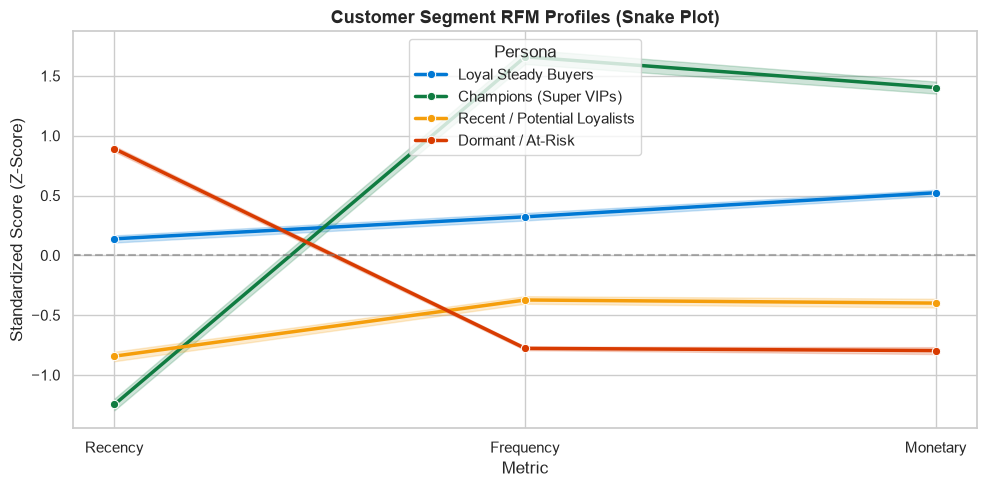

Saved snake plot to: ..\output\snake_plot_clusters.png


In [8]:
# Snake Plot
rfm_norm = pd.DataFrame(rfm_scaled, columns=["Recency", "Frequency", "Monetary"])
rfm_norm["Persona"] = rfm["Persona"]
melted_rfm = pd.melt(rfm_norm, id_vars=["Persona"], var_name="Metric", value_name="Standardized_Value")

plt.figure(figsize=(10, 5))
palette = {
    "Champions (Super VIPs)": "#107c41",
    "Loyal Steady Buyers": "#0078d4",
    "Recent / Potential Loyalists": "#f59e0b",
    "Dormant / At-Risk": "#d83b01"
}
sns.lineplot(data=melted_rfm, x="Metric", y="Standardized_Value", hue="Persona", palette=palette, marker="o", linewidth=2.5)
plt.title("Customer Segment RFM Profiles (Snake Plot)", fontsize=13, fontweight="bold")
plt.ylabel("Standardized Score (Z-Score)")
plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.tight_layout()

plot_snake_path = os.path.join(output_dir, "snake_plot_clusters.png")
plt.savefig(plot_snake_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved snake plot to: {plot_snake_path}")


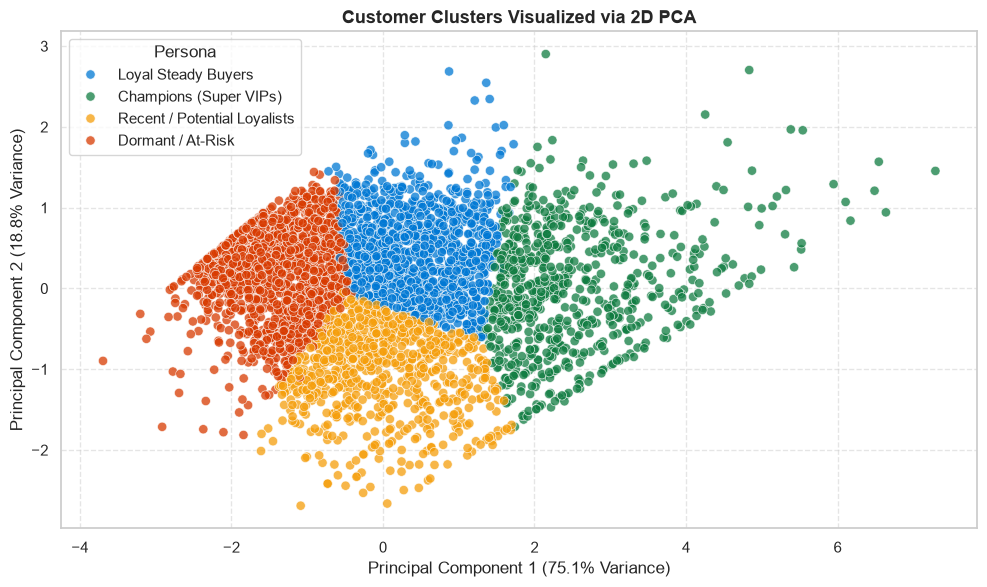

Saved PCA scatter plot to: ..\output\pca_clusters_2d.png


In [9]:
# 2D PCA Dimensionality Reduction
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(rfm_scaled)
rfm["PCA1"] = pca_coords[:, 0]
rfm["PCA2"] = pca_coords[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="Persona",
    palette=palette,
    alpha=0.75,
    s=45
)
plt.title(f"Customer Clusters Visualized via 2D PCA", fontsize=13, fontweight="bold")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plot_pca_path = os.path.join(output_dir, "pca_clusters_2d.png")
plt.savefig(plot_pca_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved PCA scatter plot to: {plot_pca_path}")


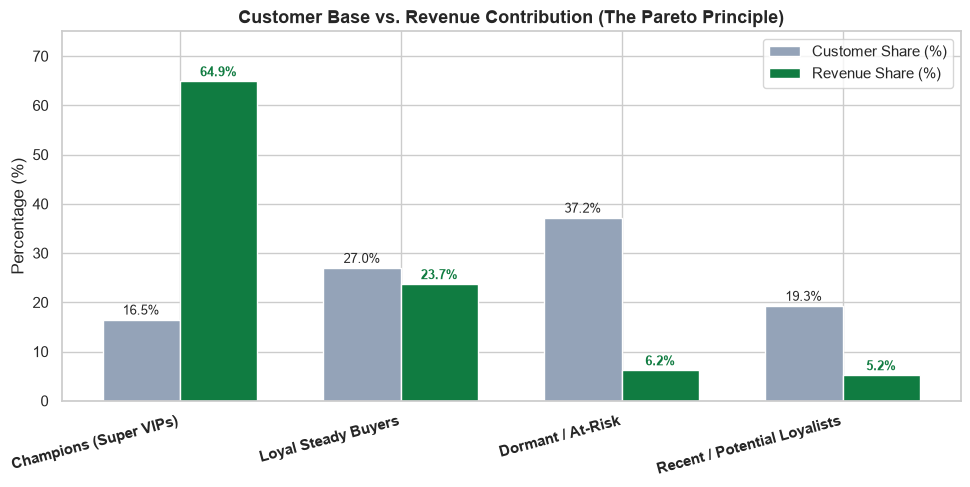

Saved Pareto revenue chart to: ..\output\cluster_revenue_breakdown.png


In [10]:
# Revenue vs Customer Share Chart
fig, ax = plt.subplots(figsize=(10, 5))
bar_width = 0.35
x = np.arange(len(profile_table))

b1 = ax.bar(x - bar_width/2, profile_table["Customer_Share_%"], bar_width, label="Customer Share (%)", color="#94a3b8")
b2 = ax.bar(x + bar_width/2, profile_table["Revenue_Share_%"], bar_width, label="Revenue Share (%)", color="#107c41")

ax.set_xticks(x)
ax.set_xticklabels(profile_table["Persona"], rotation=15, ha="right", fontweight="bold")
ax.set_ylabel("Percentage (%)")
ax.set_title("Customer Base vs. Revenue Contribution (The Pareto Principle)", fontsize=13, fontweight="bold")
ax.legend()

# Add values above bars
for bar in b1:
    ax.annotate(f"{bar.get_height():.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height() + 1), ha='center', fontsize=9)
for bar in b2:
    ax.annotate(f"{bar.get_height():.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height() + 1), ha='center', fontsize=9, fontweight='bold', color="#107c41")

plt.ylim(0, 75)
plt.tight_layout()

plot_pareto_path = os.path.join(output_dir, "cluster_revenue_breakdown.png")
plt.savefig(plot_pareto_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Pareto revenue chart to: {plot_pareto_path}")


In [11]:
# Export the final segmented dataset
output_csv = os.path.join(output_dir, "segmented_customers.csv")
rfm.to_csv(output_csv, index=False)
print(f"\nSuccessfully exported {len(rfm):,} tagged customer records to: {output_csv}")



Successfully exported 4,338 tagged customer records to: ..\output\segmented_customers.csv


## 7. Actionable Marketing Recommendations

| Customer Persona | Key Behavioral Pattern | Marketing Objective | Recommended Action Plan |
| :--- | :--- | :--- | :--- |
| 👑 **Champions (Super VIPs)** | • High Frequency (13.7 orders)<br>• Top Spend ($8,074)<br>• Bought ~12 days ago | **Retention & Advocacy** | • Exclusive VIP club & early access to new product drops.<br>• Dedicated white-glove customer support.<br>• **Do NOT discount:** They buy at full price; reward with perks instead. |
| 💎 **Loyal Steady Buyers** | • Moderate Frequency (4.1 orders)<br>• Solid Spend ($1,803)<br>• Bought ~71 days ago | **Cross-Selling & Basket Expansion** | • Personalized bundle recommendations based on purchase history.<br>• Free shipping thresholds to increase Average Order Value (AOV). |
| 🌱 **Recent / Potential Loyalists** | • Low Frequency (2.1 orders)<br>• Bought very recently (~18 days ago) | **Conversion to Repeat Habit** | • Post-purchase onboarding emails & how-to guides.<br>• Time-sensitive discount (e.g. *15% off your next order in 14 days*). |
| ⚠️ **Dormant / At-Risk** | • Long Recency (182 days / 6 months)<br>• Single purchase (~1.3 orders) | **Re-Activation or Prune** | • Automated 3-part "We miss you" win-back email sequence with aggressive discount.<br>• If no engagement in 90 days, unsubscribe to protect email deliverability. |
